# Lab 5: Clustering Techniques Using DBSCAN and Hierarchical Clustering**Student:** Xhon Pelushi**Course:** MSCS-634-B01 — Advanced Big Data and Data Mining**University:** University of the Cumberlands**Date:** November 22, 2026

## Step 1: Data Preparation and Exploration

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, homogeneity_score, completeness_score
from scipy.cluster.hierarchy import dendrogram, linkage
import warnings
warnings.filterwarnings('ignore')

# Load the Wine dataset
wine = load_wine()
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = wine.target

print("Wine Dataset Shape:", X.shape)
print("Number of classes:", len(np.unique(y)))
print("Class distribution:")
for i, name in enumerate(wine.target_names):
    print(f"  {name}: {(y == i).sum()} samples")


Wine Dataset Shape: (178, 13)
Number of classes: 3
Class distribution:
  class_0: 59 samples
  class_1: 71 samples
  class_2: 48 samples


In [2]:
# Examine the dataset structure
print("Dataset Info:")
print(X.info())
print("\nFirst 5 rows:")
X.head()


Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
dtypes:

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [3]:
# Statistical summary
X.describe().round(2)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00
mean,13.00,2.34,2.37,19.49,99.74,2.30,2.03,0.36,1.59,5.06,0.96,2.61,746.89
std,0.81,1.12,0.27,3.34,14.28,0.63,1.00,0.12,0.57,2.32,0.23,0.71,314.91
min,11.03,0.74,1.36,10.60,70.00,0.98,0.34,0.13,0.41,1.28,0.48,1.27,278.00
25%,12.36,1.60,2.21,17.20,88.00,1.74,1.20,0.27,1.25,3.22,0.78,1.94,500.50
50%,13.05,1.87,2.36,19.50,98.00,2.36,2.13,0.34,1.56,4.69,0.96,2.78,673.50
75%,13.68,3.08,2.56,21.50,107.00,2.80,2.88,0.44,1.95,6.20,1.12,3.17,985.00
max,14.83,5.80,3.23,30.00,162.00,3.88,5.08,0.66,3.58,13.00,1.71,4.00,1680.00


In [4]:
# Standardize features for clustering
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=wine.feature_names)

print("Standardized data - first 5 rows:")
X_scaled_df.head()


Standardized data - first 5 rows:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,1.518613,-0.562250,0.232053,-1.169593,1.913905,0.808997,1.034819,-0.659563,1.224884,0.251717,0.362177,1.847920,1.013009
1,0.246290,-0.499413,-0.827996,-2.490847,0.018145,0.568648,0.733629,-0.820719,-0.544721,-0.293321,0.406051,1.113449,0.965242
2,0.196879,0.021231,1.109334,-0.268738,0.088358,0.808997,1.215533,-0.498407,2.135968,0.269020,0.318304,0.788587,1.395148
3,1.691550,-0.346811,0.487926,-0.809251,0.930918,2.491446,1.466525,-0.981875,1.032155,1.186068,-0.427544,1.184071,2.334574
4,0.295700,0.227694,1.840403,0.451946,1.281985,0.808997,0.663351,0.226796,0.401404,-0.319276,0.362177,0.449601,-0.037874


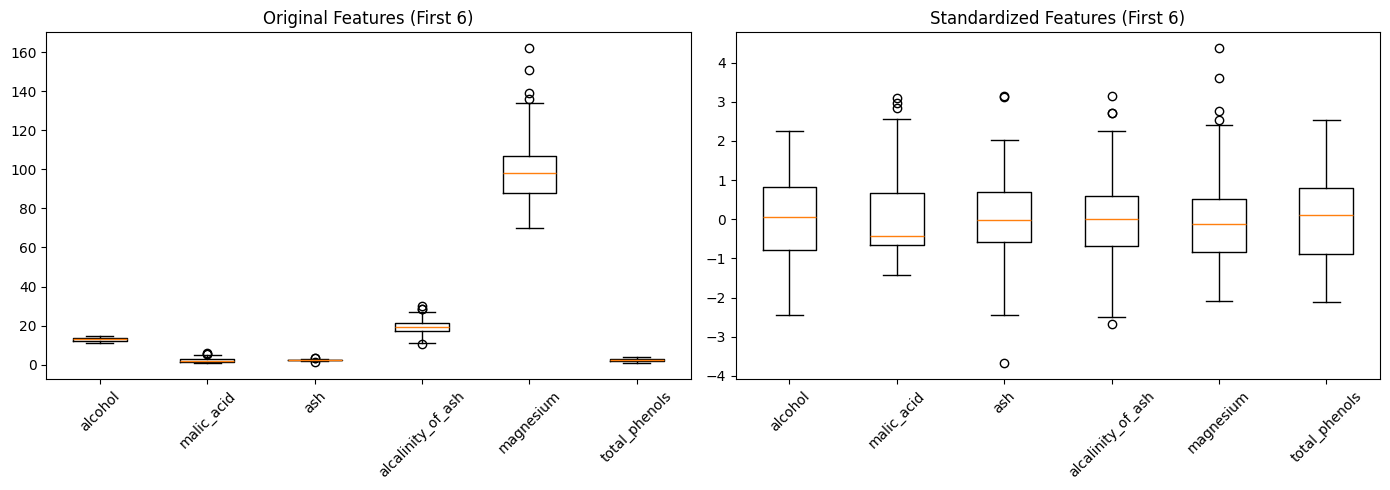

In [5]:
# Visualize feature distributions before and after scaling
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].boxplot(X.values[:, :6], labels=wine.feature_names[:6])
axes[0].set_title('Original Features (First 6)')
axes[0].tick_params(axis='x', rotation=45)

axes[1].boxplot(X_scaled[:, :6], labels=wine.feature_names[:6])
axes[1].set_title('Standardized Features (First 6)')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


## Step 2: Hierarchical Clustering

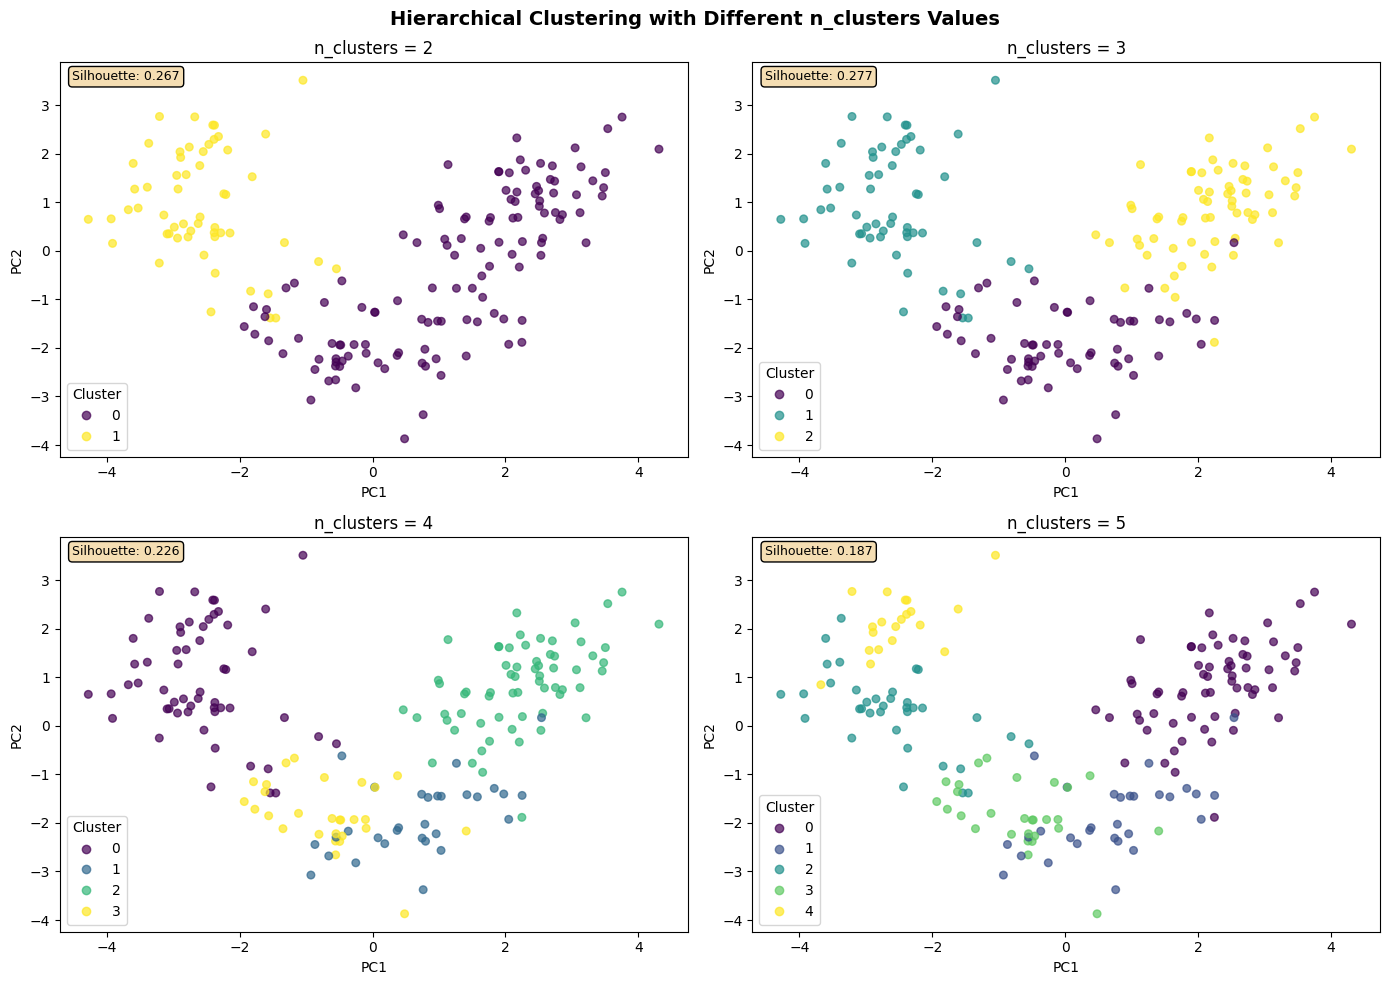

In [6]:
# Apply Agglomerative Hierarchical Clustering with different n_clusters values
n_clusters_list = [2, 3, 4, 5]
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Hierarchical Clustering with Different n_clusters Values', fontsize=14, fontweight='bold')

for idx, n in enumerate(n_clusters_list):
    ax = axes[idx // 2, idx % 2]
    hc = AgglomerativeClustering(n_clusters=n, linkage='ward')
    labels = hc.fit_predict(X_scaled)

    # Use first two principal components for visualization
    from sklearn.decomposition import PCA
    pca = PCA(n_components=2)
    X_pca = pca.fit_transform(X_scaled)

    scatter = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap='viridis', alpha=0.7, s=30)
    ax.set_title(f'n_clusters = {n}')
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
    ax.legend(*scatter.legend_elements(), title='Cluster')

    sil = silhouette_score(X_scaled, labels)
    ax.text(0.02, 0.98, f'Silhouette: {sil:.3f}', transform=ax.transAxes,
            verticalalignment='top', fontsize=9, bbox=dict(boxstyle='round', facecolor='wheat'))

plt.tight_layout()
plt.show()


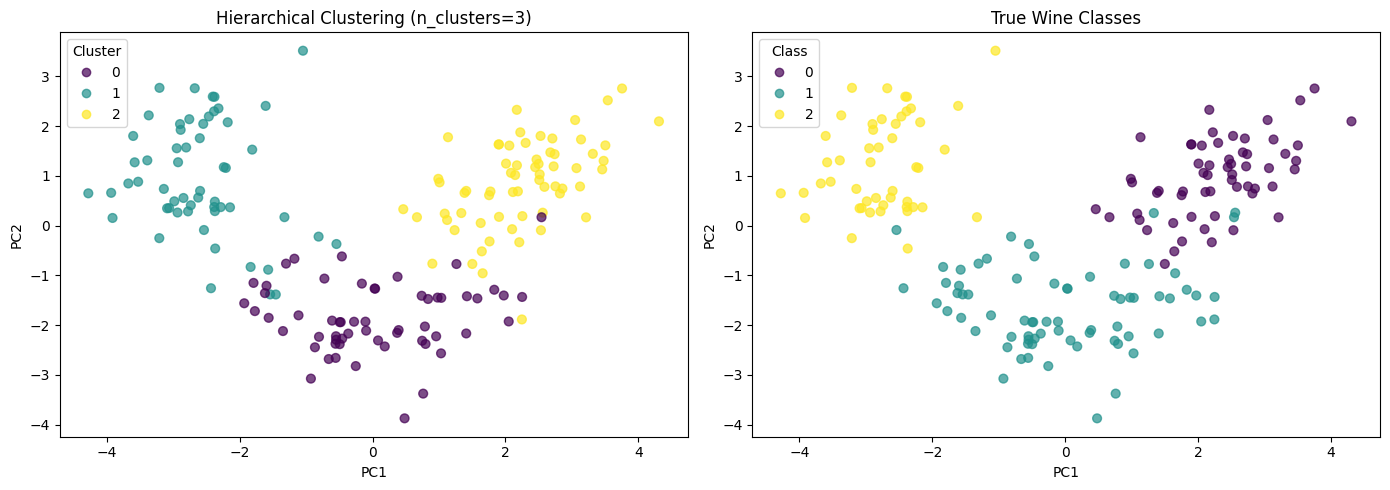

Silhouette Score: 0.2774
Homogeneity Score: 0.7904
Completeness Score: 0.7825


In [7]:
# Best hierarchical clustering with n_clusters=3 (matching true classes)
hc_best = AgglomerativeClustering(n_clusters=3, linkage='ward')
hc_labels = hc_best.fit_predict(X_scaled)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Predicted clusters
scatter1 = axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=hc_labels, cmap='viridis', alpha=0.7, s=40)
axes[0].set_title('Hierarchical Clustering (n_clusters=3)')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')
axes[0].legend(*scatter1.legend_elements(), title='Cluster')

# True labels
scatter2 = axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='viridis', alpha=0.7, s=40)
axes[1].set_title('True Wine Classes')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')
axes[1].legend(*scatter2.legend_elements(), title='Class')

plt.tight_layout()
plt.show()

print(f"Silhouette Score: {silhouette_score(X_scaled, hc_labels):.4f}")
print(f"Homogeneity Score: {homogeneity_score(y, hc_labels):.4f}")
print(f"Completeness Score: {completeness_score(y, hc_labels):.4f}")


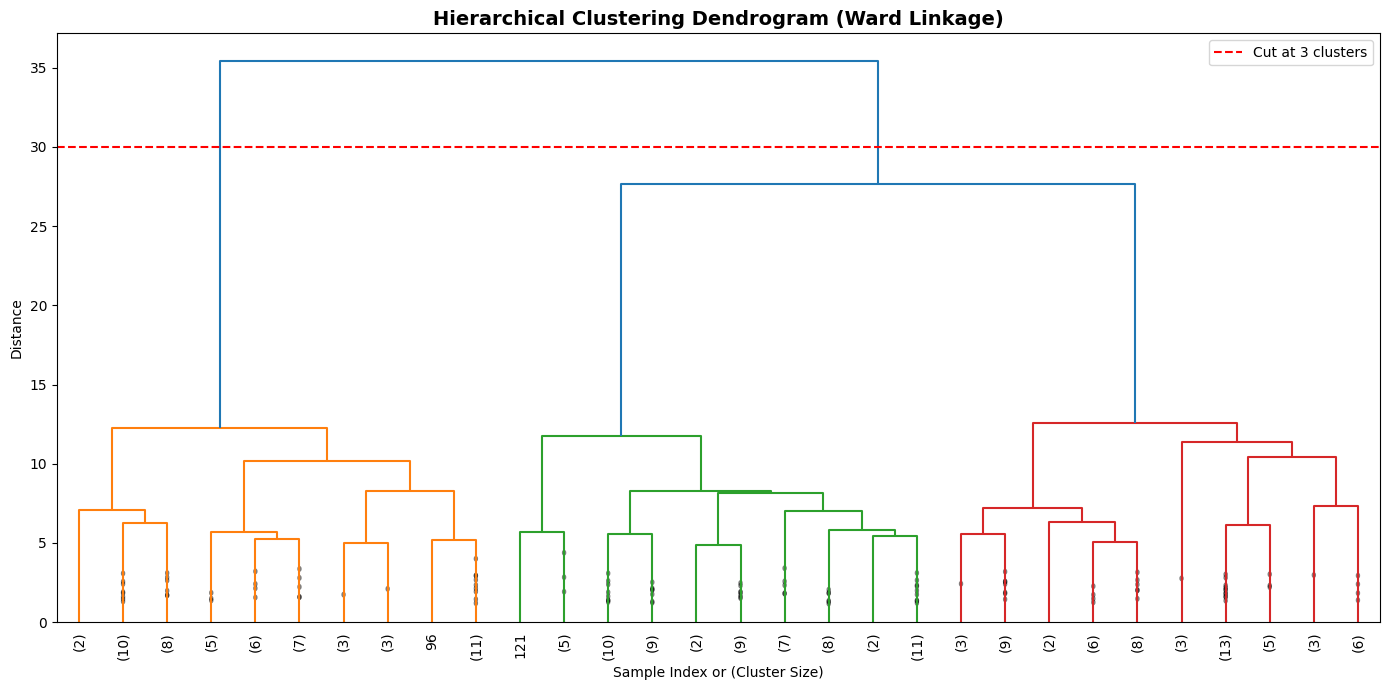

The dendrogram shows the hierarchical merging of clusters.
The red dashed line indicates where cutting produces 3 clusters,
which aligns with the known 3 wine classes in the dataset.


In [8]:
# Generate and interpret dendrogram
linked = linkage(X_scaled, method='ward')

fig, ax = plt.subplots(figsize=(14, 7))
dendrogram(linked,
           truncate_mode='lastp',
           p=30,
           leaf_rotation=90,
           leaf_font_size=10,
           show_contracted=True,
           ax=ax)
ax.set_title('Hierarchical Clustering Dendrogram (Ward Linkage)', fontsize=14, fontweight='bold')
ax.set_xlabel('Sample Index or (Cluster Size)')
ax.set_ylabel('Distance')
ax.axhline(y=30, color='r', linestyle='--', label='Cut at 3 clusters')
ax.legend()
plt.tight_layout()
plt.show()

print("The dendrogram shows the hierarchical merging of clusters.")
print("The red dashed line indicates where cutting produces 3 clusters,")
print("which aligns with the known 3 wine classes in the dataset.")


## Step 3: DBSCAN Clustering

In [9]:
# Experiment with different eps and min_samples values
eps_values = [0.5, 1.0, 1.5, 2.0]
min_samples_values = [3, 5, 7, 10]

results = []
for eps in eps_values:
    for ms in min_samples_values:
        db = DBSCAN(eps=eps, min_samples=ms)
        db_labels = db.fit_predict(X_scaled)
        n_clusters = len(set(db_labels)) - (1 if -1 in db_labels else 0)
        n_noise = (db_labels == -1).sum()
        sil = silhouette_score(X_scaled, db_labels) if n_clusters >= 2 else -1
        results.append({
            'eps': eps, 'min_samples': ms,
            'n_clusters': n_clusters, 'n_noise': n_noise,
            'silhouette': round(sil, 4)
        })

results_df = pd.DataFrame(results)
print("DBSCAN Parameter Search Results:")
results_df


DBSCAN Parameter Search Results:


,eps,min_samples,n_clusters,n_noise,silhouette
0,0.5,3,0,178,-1.0000
1,0.5,5,0,178,-1.0000
2,0.5,7,0,178,-1.0000
3,0.5,10,0,178,-1.0000
4,1.0,3,0,178,-1.0000
5,1.0,5,0,178,-1.0000
6,1.0,7,0,178,-1.0000
7,1.0,10,0,178,-1.0000
8,1.5,3,8,147,-0.2768
9,1.5,5,0,178,-1.0000


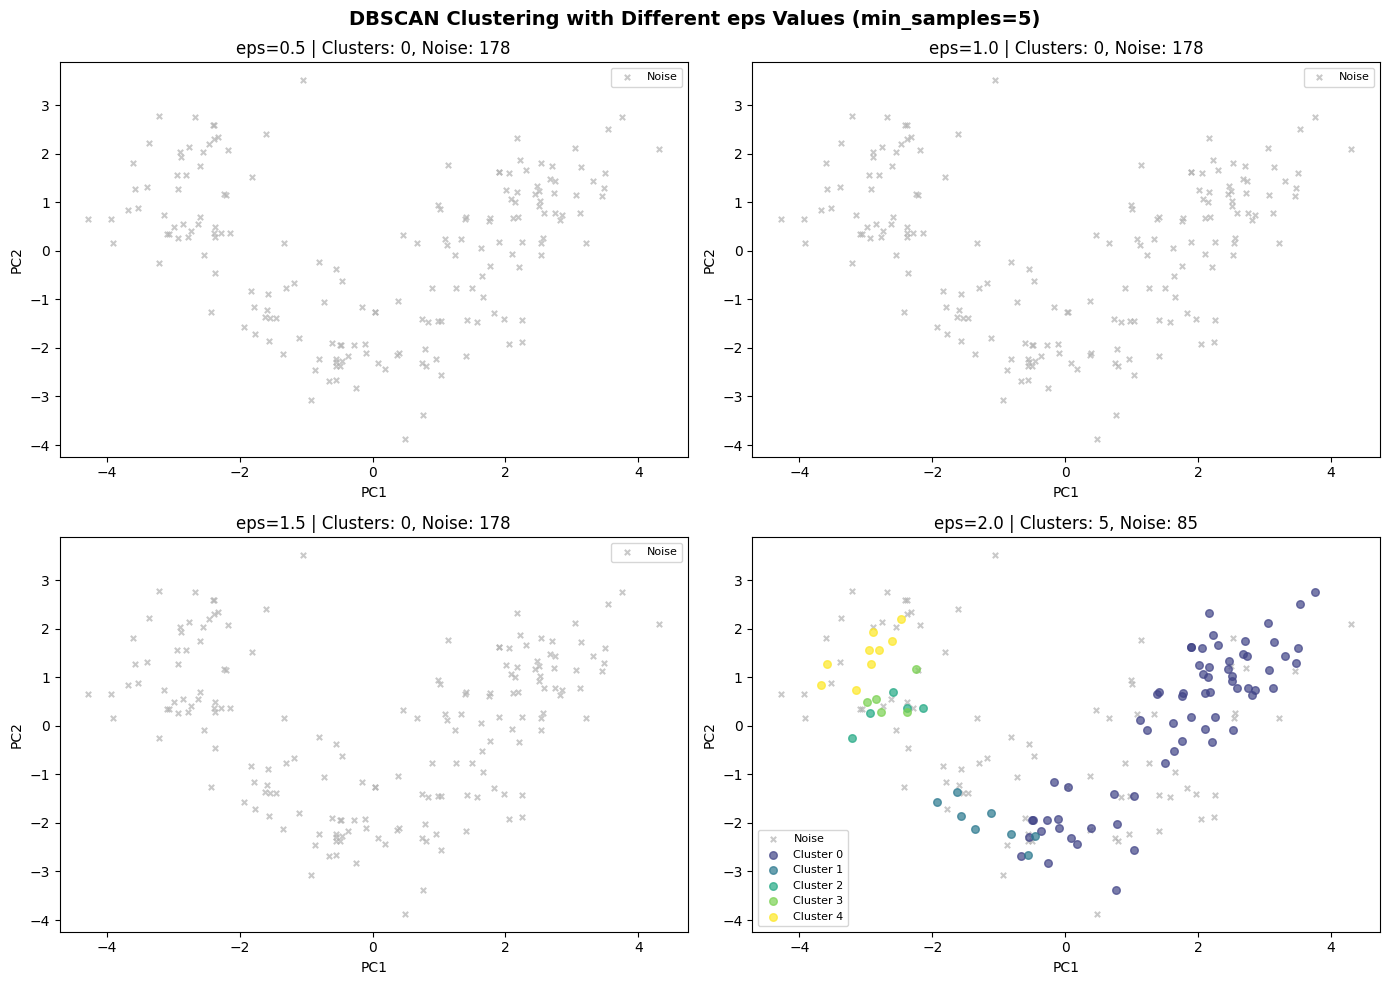

In [10]:
# Visualize DBSCAN with different eps values (fixed min_samples=5)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('DBSCAN Clustering with Different eps Values (min_samples=5)', fontsize=14, fontweight='bold')

for idx, eps in enumerate(eps_values):
    ax = axes[idx // 2, idx % 2]
    db = DBSCAN(eps=eps, min_samples=5)
    db_labels = db.fit_predict(X_scaled)

    n_clusters = len(set(db_labels)) - (1 if -1 in db_labels else 0)
    n_noise = (db_labels == -1).sum()

    # Plot clusters and noise points
    unique_labels = set(db_labels)
    colors = plt.cm.viridis(np.linspace(0, 1, len(unique_labels)))

    for k, col in zip(sorted(unique_labels), colors):
        if k == -1:
            col = [0.7, 0.7, 0.7, 1]  # Gray for noise
        mask = db_labels == k
        ax.scatter(X_pca[mask, 0], X_pca[mask, 1], c=[col], s=30 if k != -1 else 15,
                   label=f'Cluster {k}' if k != -1 else 'Noise',
                   alpha=0.7, marker='o' if k != -1 else 'x')

    ax.set_title(f'eps={eps} | Clusters: {n_clusters}, Noise: {n_noise}')
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()


In [11]:
# Best DBSCAN configuration
best_eps = 2.0
best_min_samples = 5

db_best = DBSCAN(eps=best_eps, min_samples=best_min_samples)
db_labels = db_best.fit_predict(X_scaled)

n_clusters = len(set(db_labels)) - (1 if -1 in db_labels else 0)
n_noise = (db_labels == -1).sum()

print(f"Best DBSCAN Parameters: eps={best_eps}, min_samples={best_min_samples}")
print(f"Number of clusters found: {n_clusters}")
print(f"Number of noise points: {n_noise}")

# Compute metrics (excluding noise points for silhouette)
mask = db_labels != -1
if mask.sum() > 0 and n_clusters >= 2:
    sil = silhouette_score(X_scaled[mask], db_labels[mask])
    print(f"\nSilhouette Score (excl. noise): {sil:.4f}")

hom = homogeneity_score(y, db_labels)
comp = completeness_score(y, db_labels)
print(f"Homogeneity Score: {hom:.4f}")
print(f"Completeness Score: {comp:.4f}")


Best DBSCAN Parameters: eps=2.0, min_samples=5
Number of clusters found: 5
Number of noise points: 85

Silhouette Score (excl. noise): 0.2405
Homogeneity Score: 0.3624
Completeness Score: 0.3247


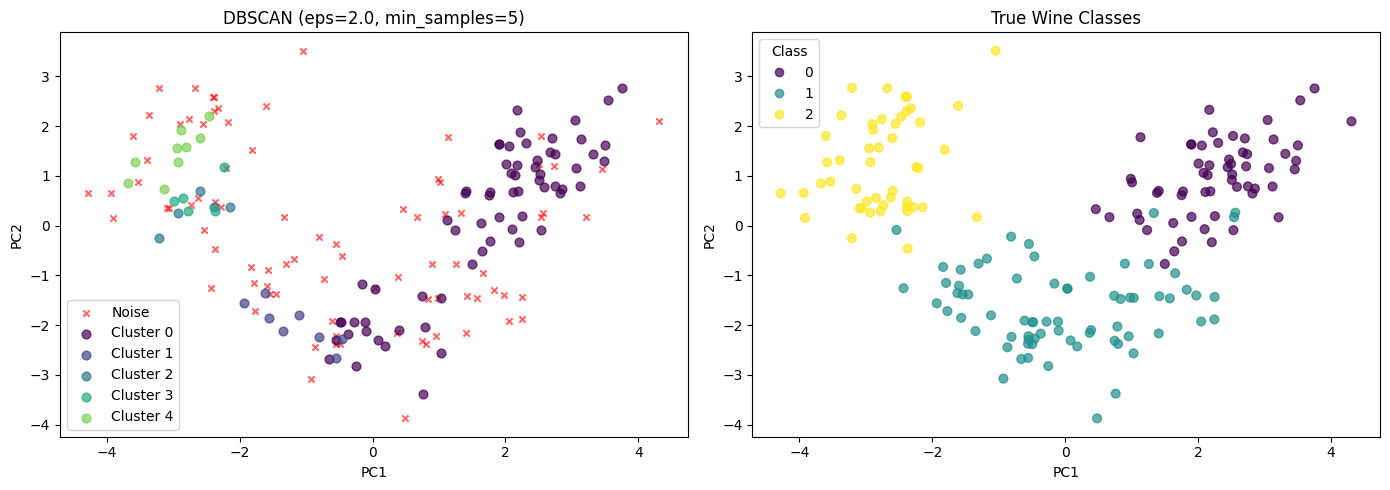

In [12]:
# Visualize best DBSCAN result with noise highlighted
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# DBSCAN clusters
unique_labels = set(db_labels)
colors = plt.cm.viridis(np.linspace(0, 1, max(len(unique_labels), 2)))

for k in sorted(unique_labels):
    mask = db_labels == k
    if k == -1:
        axes[0].scatter(X_pca[mask, 0], X_pca[mask, 1], c='red', s=20,
                        marker='x', label='Noise', alpha=0.6)
    else:
        axes[0].scatter(X_pca[mask, 0], X_pca[mask, 1], c=[colors[k]], s=40,
                        label=f'Cluster {k}', alpha=0.7)

axes[0].set_title(f'DBSCAN (eps={best_eps}, min_samples={best_min_samples})')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')
axes[0].legend()

# True labels for comparison
scatter2 = axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='viridis', alpha=0.7, s=40)
axes[1].set_title('True Wine Classes')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')
axes[1].legend(*scatter2.legend_elements(), title='Class')

plt.tight_layout()
plt.show()


## Step 4: Analysis and Insights

In [13]:
# Comparison table
print("=" * 60)
print("Comparison: Hierarchical vs DBSCAN Clustering")
print("=" * 60)

hc_sil = silhouette_score(X_scaled, hc_labels)
hc_hom = homogeneity_score(y, hc_labels)
hc_comp = completeness_score(y, hc_labels)

db_hom = homogeneity_score(y, db_labels)
db_comp = completeness_score(y, db_labels)

comparison = pd.DataFrame({
    'Metric': ['Number of Clusters', 'Noise Points', 'Silhouette Score',
               'Homogeneity Score', 'Completeness Score'],
    'Hierarchical (n=3)': [3, 0, round(hc_sil, 4), round(hc_hom, 4), round(hc_comp, 4)],
    'DBSCAN': [n_clusters, n_noise,
               round(silhouette_score(X_scaled[db_labels != -1], db_labels[db_labels != -1]), 4) if n_clusters >= 2 else 'N/A',
               round(db_hom, 4), round(db_comp, 4)]
})
comparison


Comparison: Hierarchical vs DBSCAN Clustering


,Metric,Hierarchical (n=3),DBSCAN
0,Number of Clusters,3.0000,5.0000
1,Noise Points,0.0000,85.0000
2,Silhouette Score,0.2774,0.2405
3,Homogeneity Score,0.7904,0.3624
4,Completeness Score,0.7825,0.3247


### Analysis and Discussion**Parameter Influence:**- **Hierarchical Clustering:** The `n_clusters` parameter directly controls the number of groups. With `n_clusters=3` (matching the known wine classes), Ward linkage produced the best separation. The dendrogram visualization clearly shows three natural groupings.- **DBSCAN:** The `eps` parameter controls neighborhood radius, and `min_samples` sets the minimum density threshold. Small eps values created many small clusters with excessive noise, while larger values merged clusters. The density-based approach struggles when clusters have varying densities.**Algorithm Strengths:**- **Hierarchical Clustering** produces a complete hierarchy (dendrogram) showing relationships at every level, making it interpretable and effective for datasets with clear hierarchical structure.- **DBSCAN** can discover clusters of arbitrary shape and automatically identifies noise/outlier points without requiring the number of clusters as input.**Algorithm Weaknesses:**- **Hierarchical Clustering** requires specifying the number of clusters and has O(n²) complexity, making it slow for large datasets. It cannot undo merging decisions.- **DBSCAN** is sensitive to eps and min_samples — choosing poor values produces either one giant cluster or entirely noise. It struggles with varying-density clusters, as seen in the Wine dataset where classes have different spreads.**Conclusion:** For the Wine dataset, Hierarchical Clustering with Ward linkage outperforms DBSCAN because the clusters are roughly globular and similarly dense. DBSCAN would be preferable for spatial data with irregular cluster shapes and clear density separation.